### 0. Install and Import Dependencies


In [2]:
import easyocr
import cv2
from matplotlib import pyplot as plt
import numpy as np


### 1. Read in images or video

In [3]:
IMAGE_PATH = 'test.png'

In [4]:
reader = easyocr.Reader(['en'],gpu = False)
result = reader.readtext(IMAGE_PATH)
result

Using CPU. Note: This module is much faster with a GPU.
c:\Users\Jason Lee\OneDrive - University of South Florida\Personal\jupyter\Machine_Learning\$ML_PATH\CIS4900\.venv\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[([[np.int32(49), np.int32(21)],
   [np.int32(525), np.int32(21)],
   [np.int32(525), np.int32(90)],
   [np.int32(49), np.int32(90)]],
  'KITCHEN CHECK',
  np.float64(0.7081545038863025)),
 ([[np.int32(42), np.int32(92)],
   [np.int32(88), np.int32(92)],
   [np.int32(88), np.int32(116)],
   [np.int32(42), np.int32(116)]],
  'Date',
  np.float64(0.9018841231257533)),
 ([[np.int32(122), np.int32(94)],
   [np.int32(172), np.int32(94)],
   [np.int32(172), np.int32(120)],
   [np.int32(122), np.int32(120)]],
  'Table',
  np.float64(0.9999764893687645)),
 ([[np.int32(282), np.int32(98)],
   [np.int32(340), np.int32(98)],
   [np.int32(340), np.int32(122)],
   [np.int32(282), np.int32(122)]],
  'Server',
  np.float64(0.99998603255233)),
 ([[np.int32(267), np.int32(103)],
   [np.int32(553), np.int32(103)],
   [np.int32(553), np.int32(165)],
   [np.int32(267), np.int32(165)]],
  '12.24689657',
  np.float64(0.48548273637729167)),
 ([[np.int32(18), np.int32(164)],
   [np.int32(558), np.int32(164)],

### 2. Draw Results

In [15]:
table_top_left = tuple(result[2][0][0])
table_bottem_right = tuple(result[2][0][2])
# table_top_right = tuple(result[2][0][1])
# table_bottme_left = tuple(result[2][0][3])
table_text = result[2][1] 
#0 is the nested list with the viewing rectangle
#1 is the result of the OCR
#2 is the confidence in that result
font = cv2.FONT_HERSHEY_SIMPLEX
table_text
print(table_top_left)
print(table_bottem_right)

(np.int32(122), np.int32(94))
(np.int32(172), np.int32(120))


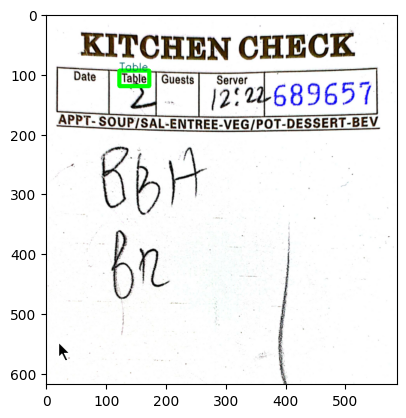

In [16]:
img = cv2.imread(IMAGE_PATH)
img = cv2.rectangle(img,table_top_left,table_bottem_right,(0,255,0),5)
img = cv2.putText(img,table_text,table_top_left,font,.6,(0,100,100),1,cv2.LINE_AA)
plt.imshow(img)

### 3. Multiple Lines

<function matplotlib.pyplot.show(close=None, block=None)>

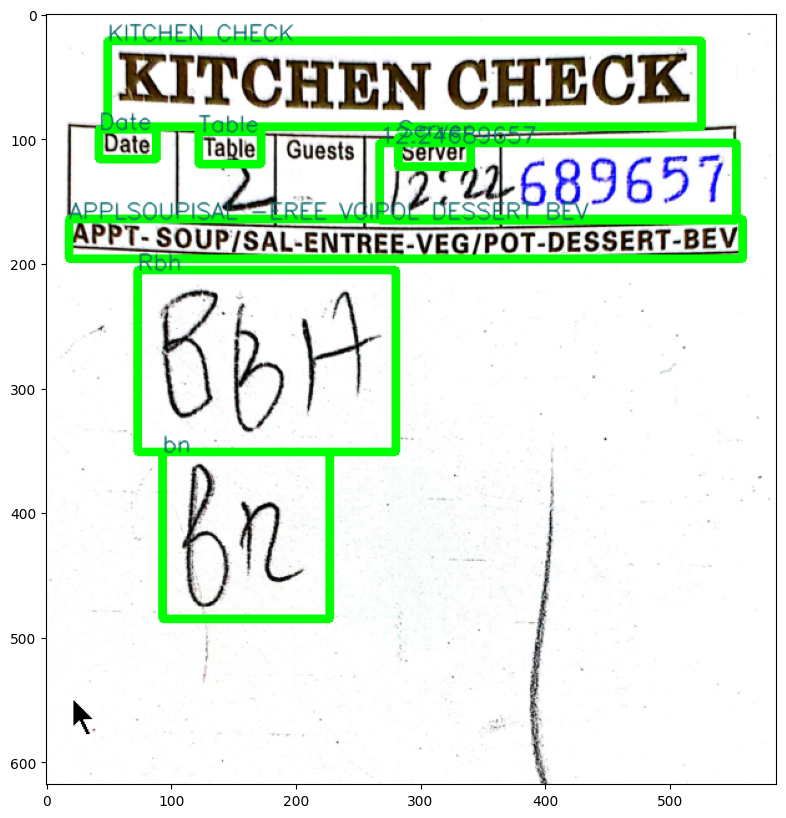

In [35]:
img = cv2.imread(IMAGE_PATH)
for x in range(len(result)-1):
    top_left = tuple(result[x][0][0])
    bottem_right = tuple(result[x][0][2])

    text = result[x][1] 
    #0 is the nested list with the viewing rectangle
    #1 is the result of the OCR
    #2 is the confidence in that result
    font = cv2.FONT_HERSHEY_SIMPLEX

    
    img = cv2.rectangle(img,top_left,bottem_right,(0,255,0),5)
    img = cv2.putText(img,text,top_left,font,.6,(0,100,100),1,cv2.LINE_AA)

plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show


In [1]:
import cv2
import matplotlib.pyplot as plt

# Load image
img = cv2.imread(IMAGE_PATH)

# Process each detection
for detection in result:
    # Extract coordinates and text
    points, text = detection[:2]
    top_left = tuple(int(coord) for coord in points[0])
    bottom_right = tuple(int(coord) for coord in points[2])

    # Draw bounding box and text
    img = cv2.rectangle(img, top_left, bottom_right, (0, 255, 0), 5)
    img = cv2.putText(
        img, 
        text, 
        top_left, 
        cv2.FONT_HERSHEY_SIMPLEX, 
        4, 
        (255, 255, 255), 
        2, 
        cv2.LINE_AA
    )

# Display results
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.show()

NameError: name 'IMAGE_PATH' is not defined